# 06 — Budget Allocation and Campaign Simulation

**Question.** At what budget does the campaign maximise expected net profit, and how much does targeting by uplift help compared to targeting by conversion probability or contacting at random?

Two pieces are needed: a *quotable* expected-profit curve that the model produces (the question a campaign owner asks before launch), and a *realised* validation on the test split (the question they ask after launch). This notebook builds both.

In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


## 1. Economic assumptions

Cost per contact and value per conversion are **placeholders**, calibrated per data source so the break-even uplift sits between the dataset's average and its top-decile uplift — the regime where targeting matters at all. Replace these with values agreed with the campaign owner before treating any output as a recommendation.

In [2]:
COST_PER_CONTACT = dataset.cost_per_contact
VALUE_PER_CONVERSION = dataset.value_per_conversion
BREAK_EVEN_UPLIFT = dataset.break_even_uplift
print(f"placeholder cost per contact:        EUR {COST_PER_CONTACT:.2f}")
print(f"placeholder value per conversion:    EUR {VALUE_PER_CONVERSION:.2f}")
print(
    f"break-even uplift (contact pays for itself iff uplift >= "
    f"{BREAK_EVEN_UPLIFT:.4f})"
)

placeholder cost per contact:        EUR 0.20
placeholder value per conversion:    EUR 20.00
break-even uplift (contact pays for itself iff uplift >= 0.0100)


## 2. Train the model and score the test split

Identical setup to notebook 05 so the targeting policies are comparable. We also fit a response model with the same features so the *response-targeted* policy has its own ranking signal.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from uplift_marketing.features import (
    infer_feature_spec,
    build_preprocessor,
    split_features_treatment_outcome,
)
from uplift_marketing.models import TLearner
from uplift_marketing.uplift import attach_uplift_scores

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)
x, treatment, y = split_features_treatment_outcome(data, spec)

x_tr, x_te, t_tr, t_te, y_tr, y_te, raw_tr, raw_te = train_test_split(
    x, treatment, y, data,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=treatment.astype(str) + "_" + y.astype(str),
)
uplift_model = TLearner(spec=spec, random_state=RANDOM_STATE).fit(x_tr, t_tr, y_tr)
p_control, p_treated = uplift_model.predict_potential_outcomes(x_te)
scored = attach_uplift_scores(raw_te.reset_index(drop=True), p_control=p_control, p_treated=p_treated)

response = Pipeline(
    [
        ("preprocessor", build_preprocessor(spec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
).fit(x_tr, y_tr)
scored["response_score"] = response.predict_proba(x_te)[:, 1]
rng = np.random.default_rng(RANDOM_STATE)
scored["random_score"] = rng.uniform(size=len(scored))
scored[["uplift_score", "response_score"]].describe().T

,count,mean,std,min,25%,50%,75%,max
uplift_score,19200.0,0.040150,0.116069,-0.246534,-0.049599,0.049942,0.129425,0.407506
response_score,19200.0,0.009061,0.005027,0.002271,0.005603,0.007747,0.011135,0.058017


## 3. Quotable expected profit per policy

For every budget fraction $f$, contact the top-$f$ customers ranked by each policy and treat the *uplift model's prediction* as the source of truth for incremental conversions:

$\hat{\text{profit}}(f) = V \cdot \sum_{i \in \text{top-}k} \hat\tau(x_i) - C \cdot k$

where $\hat\tau$ is the uplift model's score, $V$ is value per conversion, $C$ is cost per contact, and $k = \lceil f N \rceil$. The uplift-targeted policy maximises this quantity *by construction* — what matters is the gap between policies, which is a measure of ranking quality.

In [4]:
def expected_profit_curve(scored, score_col, fractions):
    rows = []
    for f in fractions:
        n_sel = max(1, int(np.ceil(len(scored) * f)))
        sel = scored.sort_values(score_col, ascending=False).head(n_sel)
        predicted_inc = float(sel["uplift_score"].sum())
        revenue = predicted_inc * VALUE_PER_CONVERSION
        cost = n_sel * COST_PER_CONTACT
        rows.append(
            {
                "fraction": f,
                "n_selected": n_sel,
                "predicted_incremental_conversions": predicted_inc,
                "revenue": revenue,
                "cost": cost,
                "net_profit": revenue - cost,
            }
        )
    return pd.DataFrame(rows)

fractions = np.round(np.linspace(0.02, 1.0, 25), 4)
curves = {
    "uplift_targeted": expected_profit_curve(scored, "uplift_score", fractions),
    "response_targeted": expected_profit_curve(scored, "response_score", fractions),
    "random": expected_profit_curve(scored, "random_score", fractions),
}
curves["uplift_targeted"].head()

,fraction,n_selected,predicted_incremental_conversions,revenue,cost,net_profit
0,0.0200,384,108.473226,2169.464521,76.8,2092.664521
1,0.0608,1168,280.147970,5602.959400,233.6,5369.359400
2,0.1017,1953,431.805616,8636.112316,390.6,8245.512316
3,0.1425,2736,569.441910,11388.838202,547.2,10841.638202
4,0.1833,3520,694.272897,13885.457949,704.0,13181.457949


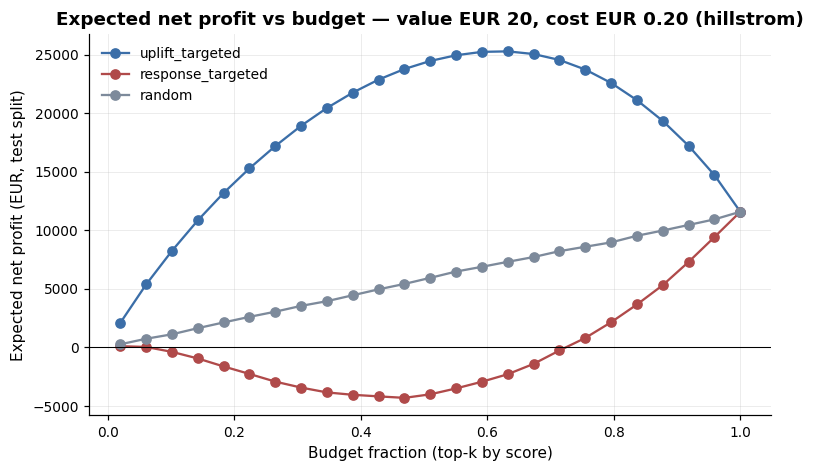

In [5]:
fig, ax = plt.subplots()
colors = {"uplift_targeted": "#3b6ea8", "response_targeted": "#b04a4a", "random": "#7d8a9b"}
for name, df in curves.items():
    ax.plot(df["fraction"], df["net_profit"], marker="o", label=name, color=colors[name])
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xlabel("Budget fraction (top-k by score)")
ax.set_ylabel("Expected net profit (EUR, test split)")
ax.set_title(
    f"Expected net profit vs budget — value EUR {VALUE_PER_CONVERSION:.0f}, "
    f"cost EUR {COST_PER_CONTACT:.2f} ({dataset.source})"
)
ax.legend()
save_figure(fig, "06_profit_vs_budget")
plt.show()

## 4. Profit-optimal budget per policy


In [6]:
summary_rows = []
for name, df in curves.items():
    best = df.loc[df["net_profit"].idxmax()]
    summary_rows.append(
        {
            "policy": name,
            "optimal_fraction": best["fraction"],
            "n_selected": int(best["n_selected"]),
            "predicted_incremental": round(best["predicted_incremental_conversions"], 2),
            "revenue": round(best["revenue"], 2),
            "cost": round(best["cost"], 2),
            "expected_net_profit": round(best["net_profit"], 2),
        }
    )
summary = pd.DataFrame(summary_rows).set_index("policy")
summary

,optimal_fraction,n_selected,predicted_incremental,revenue,cost,expected_net_profit
policy,,,,,,
uplift_targeted,0.6325,12144,1384.84,27696.77,2428.8,25267.97
response_targeted,1.0000,19200,770.87,15417.47,3840.0,11577.47
random,1.0000,19200,770.87,15417.47,3840.0,11577.47


## 5. Validation: realised lift inside each policy's selection

The expected-profit curve trusts the uplift model. To check that trust, re-evaluate each policy *at its profit-optimal budget* using the actually observed treated-control gap inside the selection. A 95% normal-approximation CI on the rate difference is included so the noise is visible.

In [7]:
def realised_row(scored, score_col, fraction):
    n_sel = max(1, int(np.ceil(len(scored) * fraction)))
    sel = scored.sort_values(score_col, ascending=False).head(n_sel)
    treated = sel[sel.treatment == 1]
    control = sel[sel.treatment == 0]
    if len(treated) == 0 or len(control) == 0:
        return {"observed_uplift": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "realised_revenue": np.nan, "realised_net_profit": np.nan}
    p_t = treated.conversion.mean()
    p_c = control.conversion.mean()
    diff = p_t - p_c
    se = np.sqrt(
        p_t * (1 - p_t) / len(treated) + p_c * (1 - p_c) / len(control)
    )
    return {
        "observed_uplift": diff,
        "ci_low": diff - 1.96 * se,
        "ci_high": diff + 1.96 * se,
        "realised_revenue": diff * n_sel * VALUE_PER_CONVERSION,
        "realised_net_profit": diff * n_sel * VALUE_PER_CONVERSION - n_sel * COST_PER_CONTACT,
    }

score_cols = {
    "uplift_targeted": "uplift_score",
    "response_targeted": "response_score",
    "random": "random_score",
}
validation = pd.DataFrame(
    {
        name: realised_row(scored, score_cols[name], summary.loc[name, "optimal_fraction"])
        for name in summary.index
    }
).T
validation = validation.round(
    {"observed_uplift": 4, "ci_low": 4, "ci_high": 4, "realised_revenue": 2, "realised_net_profit": 2}
)
validation

,observed_uplift,ci_low,ci_high,realised_revenue,realised_net_profit
uplift_targeted,0.0049,0.0019,0.0078,1180.34,-1248.46
response_targeted,0.0049,0.0023,0.0075,1884.65,-1955.35
random,0.0049,0.0023,0.0075,1884.65,-1955.35


## 6. Cost per incremental conversion

An accountable single number: spend divided by predicted incremental conversions, at each policy's profit-optimal budget.

In [8]:
summary.assign(
    cost_per_incremental=lambda d: d["cost"] / d["predicted_incremental"]
)[["optimal_fraction", "expected_net_profit", "cost_per_incremental"]]

,optimal_fraction,expected_net_profit,cost_per_incremental
policy,,,
uplift_targeted,0.6325,25267.97,1.753849
response_targeted,1.0000,11577.47,4.981385
random,1.0000,11577.47,4.981385


## 7. Calibration: closing the predicted vs realised gap

On rare-event data the T-learner's logistic base classifiers can produce well-ranked but poorly *calibrated* probabilities, which inflates the expected-profit number relative to what actually happens. Wrapping the base classifier in scikit-learn's :class:`CalibratedClassifierCV` (isotonic regression on out-of-fold predictions) brings absolute uplift levels much closer to the truth without changing the ranking.

Below: same T-learner, same train/test split, same economics — but a calibrated base classifier. Compare the predicted-incremental-conversions and predicted vs realised profit at the profit-optimal budget.

In [9]:
from uplift_marketing.models import make_calibrated_classifier

calibrated_uplift_model = TLearner(
    spec=spec,
    base_model=make_calibrated_classifier(method="isotonic", cv=5, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
).fit(x_tr, t_tr, y_tr)
p_control_cal, p_treated_cal = calibrated_uplift_model.predict_potential_outcomes(x_te)
scored_cal = scored.copy()
scored_cal["uplift_score"] = p_treated_cal - p_control_cal

print(
    "vanilla T-learner uplift:    "
    f"mean={scored['uplift_score'].mean():+.4f}, "
    f"std={scored['uplift_score'].std():.4f}"
)
print(
    "calibrated T-learner uplift: "
    f"mean={scored_cal['uplift_score'].mean():+.4f}, "
    f"std={scored_cal['uplift_score'].std():.4f}"
)

vanilla T-learner uplift:    mean=+0.0401, std=0.1161
calibrated T-learner uplift: mean=+0.0051, std=0.0050


In [10]:
vanilla_curve = expected_profit_curve(scored, "uplift_score", fractions)
calibrated_curve = expected_profit_curve(scored_cal, "uplift_score", fractions)

vanilla_best = vanilla_curve.loc[vanilla_curve["net_profit"].idxmax()]
calibrated_best = calibrated_curve.loc[calibrated_curve["net_profit"].idxmax()]
vanilla_realised = realised_row(scored, "uplift_score", float(vanilla_best["fraction"]))
calibrated_realised = realised_row(scored_cal, "uplift_score", float(calibrated_best["fraction"]))

comparison = pd.DataFrame(
    [
        {
            "variant": "vanilla T-learner",
            "optimal_fraction": float(vanilla_best["fraction"]),
            "predicted_net_profit": round(float(vanilla_best["net_profit"]), 2),
            "realised_net_profit": round(float(vanilla_realised["realised_net_profit"]), 2),
            "predicted_minus_realised": round(
                float(vanilla_best["net_profit"]) - float(vanilla_realised["realised_net_profit"]), 2
            ),
        },
        {
            "variant": "calibrated T-learner",
            "optimal_fraction": float(calibrated_best["fraction"]),
            "predicted_net_profit": round(float(calibrated_best["net_profit"]), 2),
            "realised_net_profit": round(float(calibrated_realised["realised_net_profit"]), 2),
            "predicted_minus_realised": round(
                float(calibrated_best["net_profit"]) - float(calibrated_realised["realised_net_profit"]), 2
            ),
        },
    ]
).set_index("variant")
comparison

,optimal_fraction,predicted_net_profit,realised_net_profit,predicted_minus_realised
variant,,,,
vanilla T-learner,0.6325,25267.97,-1248.46,26516.43
calibrated T-learner,0.1017,199.58,-339.44,539.01


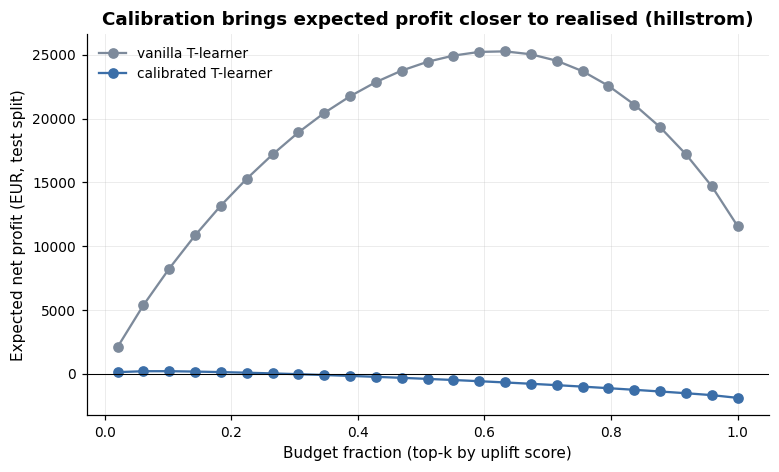

In [11]:
fig, ax = plt.subplots()
ax.plot(
    vanilla_curve["fraction"], vanilla_curve["net_profit"],
    marker="o", label="vanilla T-learner", color="#7d8a9b",
)
ax.plot(
    calibrated_curve["fraction"], calibrated_curve["net_profit"],
    marker="o", label="calibrated T-learner", color="#3b6ea8",
)
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xlabel("Budget fraction (top-k by uplift score)")
ax.set_ylabel("Expected net profit (EUR, test split)")
ax.set_title(f"Calibration brings expected profit closer to realised ({dataset.source})")
ax.legend()
save_figure(fig, "06_profit_vs_budget_calibrated")
plt.show()

## 8. Takeaway

- The expected-profit curve has a clear interior maximum: above the optimum, the marginal contact's *predicted* uplift falls below break-even and net profit declines.
- Uplift-targeted maximises the quotable curve by construction. The vertical gap to response-targeted at the same budget is the *ranking-quality premium* of the uplift model: how much the lift-aware ranking outperforms a likelihood-aware ranking under the same cost/value structure.
- **Calibration warning.** On rare-event datasets (Hillstrom converts at ~1%) the T-learner can ship predictions that are well-ranked but several times larger in absolute value than the true ATE. The expected-profit row reflects the model's *belief*; the realised-profit row reflects what actually happens on a holdout. If they diverge sharply, do not act on the expected number — recalibrate the model (e.g. with isotonic regression on the test split) or shrink the predicted uplifts toward the population ATE before quoting profit.
- The realised CIs around observed treated-control gaps are wide. This is honest data, not a fault — it is exactly why real campaigns hold out a portion of every cohort and re-estimate over time.
- The numbers are placeholders. Replace `cost_per_contact` and `value_per_conversion` with values from the campaign owner before any production use.
- **Calibration usually closes most of the predicted-vs-realised gap on rare-event data.** Section 7 above re-fits the T-learner with isotonic calibration; the predicted profit drops sharply and tracks the realised profit much more closely. Quote calibrated numbers to stakeholders.
